In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error

In [4]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/mobile.csv")

In [6]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [18]:
print(" Missing value check")
print(df.isnull().sum())
print("\n Duplicated value check")
print(df.duplicated().sum())
print("\n Target class 분포")
print(df['battery_power'].value_counts(normalize=True)*100)

 Missing value check
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

 Duplicated value check
0

 Target class 분포
battery_power
1589    0.30
1872    0.30
618     0.30
772     0.25
1063    0.25
        ... 
590     0.05
544     0.05
1279    0.05
1749    0.05
1405    0.05
Name: proportion, Length: 1094, dtype: float64


In [10]:
X=df.drop('battery_power',axis=1).values
y=df['battery_power'].values

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [11]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

In [12]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

history = model.fit(X_train, y_train,
                    epochs=100,
                    batch_size=16,
                    validation_split=0.2,
                    verbose=1)


Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 1705526.2500 - mae: 1230.7804 - val_loss: 1801489.3750 - val_mae: 1262.8566
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1664782.2500 - mae: 1214.1273 - val_loss: 1727307.7500 - val_mae: 1233.2008
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1538528.1250 - mae: 1161.2378 - val_loss: 1538081.3750 - val_mae: 1154.1013
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1284274.1250 - mae: 1044.5114 - val_loss: 1215602.6250 - val_mae: 1004.7811
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 919818.5000 - mae: 851.7596 - val_loss: 817428.1250 - val_mae: 782.6158
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 552554.1875 - mae: 618.0741 - val_loss: 481939.9375 - val_mae: 567.5729
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 313726.1562 - mae: 457.7026 - val_loss: 303556.3125 - val_mae: 450.1358
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 218814.2

In [15]:
y_prob=model.predict(X_test)
y_pred=y_prob.flatten()

mse=mean_squared_error(y_test,y_pred)
print("MSE:",mse)
rmse=root_mean_squared_error(y_test,y_pred)
print("RMSE:",rmse)
mae=mean_absolute_error(y_test,y_pred)
print("MAE:",mae)
r2=r2_score(y_test,y_pred)
print("R2",r2)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
MSE: 144133.734375
RMSE: 379.64947509765625
MAE: 305.4291076660156
R2 0.23486638069152832


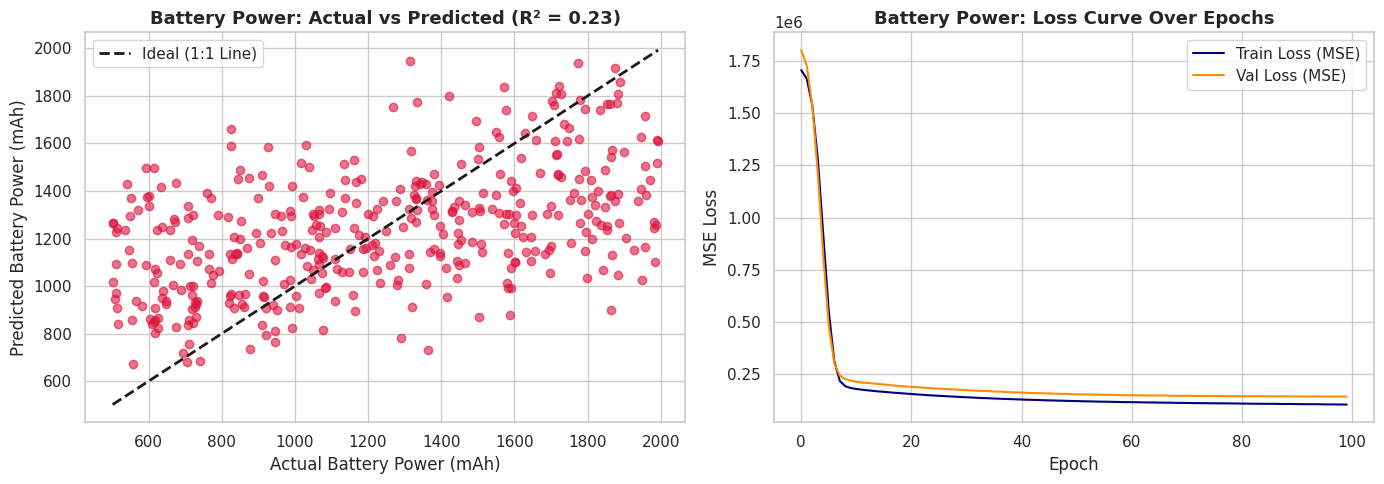

In [21]:
import seaborn as sns
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# [그래프 1] 실제값 vs 예측값 (Actual vs Predicted)
axes[0].scatter(y_test, y_pred, alpha=0.6, color='crimson')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label='Ideal (1:1 Line)')
axes[0].set_title('Battery Power: Actual vs Predicted (R² = 0.23)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Actual Battery Power (mAh)')
axes[0].set_ylabel('Predicted Battery Power (mAh)')
axes[0].legend()

# [그래프 2] Epoch별 Loss 감소 곡선 (Loss Curve)
axes[1].plot(history.history['loss'], label='Train Loss (MSE)', color='navy')
axes[1].plot(history.history['val_loss'], label='Val Loss (MSE)', color='darkorange')
axes[1].set_title('Battery Power: Loss Curve Over Epochs', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

In [28]:
battery_corr = df.corr()['battery_power'].sort_values(ascending=False)
print(battery_corr)

battery_power    1.000000
price_range      0.200723
talk_time        0.052510
m_dep            0.034085
fc               0.033334
pc               0.031441
four_g           0.015665
px_height        0.014901
three_g          0.011522
clock_speed      0.011482
blue             0.011252
mobile_wt        0.001844
ram             -0.000653
int_memory      -0.004004
wifi            -0.008343
px_width        -0.008402
touch_screen    -0.010516
sc_w            -0.021421
n_cores         -0.029727
sc_h            -0.029959
dual_sim        -0.041847
Name: battery_power, dtype: float64


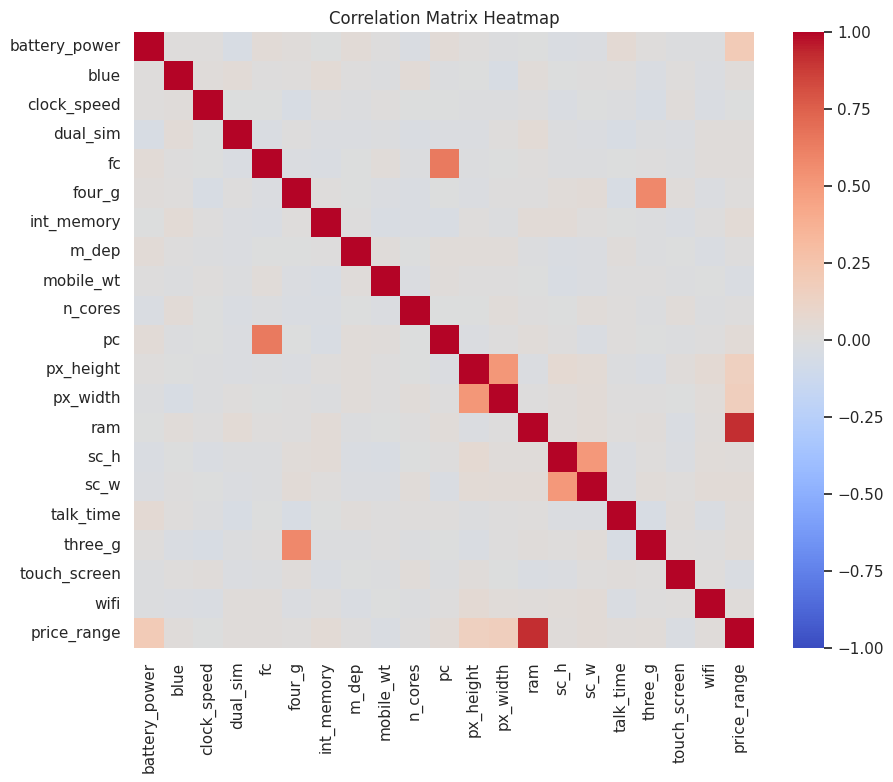

In [27]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix Heatmap')
plt.show()

모델 학습 실패 원인
1. 상관관계의 부재
- battery_power와 다른 변수간 상관계수는 대부분 약한 상관관계이다.
2.단순 평균 찍기 수준의 성능
- 배터리 데이터 전체의 표준편자 대비 모델 오차 감소폭이 매우 적다. 딥러닝 모델이 패턴을 학습한 것이 아니라 단순 평균값 근처로 때려 맞히고 있음을 의미


battery_power가 회귀의 라벨로 부적합하다.
